[INFO] [1722279174.269583644] [rosbag2_storage]: Opened database '/home/andrea/workspaces/appl_ws/bags/overtaking/DWA/scenario_2/scenario_2_0.db3' for READ_ONLY.
[INFO] [1722279174.567858339] [rosbag2_storage]: Opened database '/home/andrea/workspaces/appl_ws/bags/overtaking/DWA/scenario_2/scenario_2_0.db3' for READ_ONLY.
[INFO] [1722279174.726633637] [rosbag2_storage]: Opened database '/home/andrea/workspaces/appl_ws/bags/overtaking/DWA/scenario_2/scenario_2_0.db3' for READ_ONLY.
[INFO] [1722279175.285096728] [rosbag2_storage]: Opened database '/home/andrea/workspaces/appl_ws/bags/overtaking/DWA/scenario_2/scenario_2_0.db3' for READ_ONLY.
/tmp/ipykernel_1006353/2724662538.py:23: FutureWarning: DataFrame.interpolate with object dtype is deprecated and will raise in a future version. Call obj.infer_objects(copy=False) before interpolating instead.
  df_interpolated = df.interpolate(method='cubicspline', limit_direction='both')


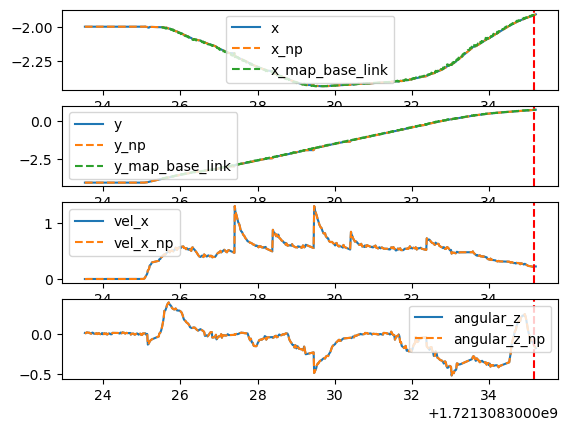

In [2]:
from social_evaluation.utils import *
from matplotlib import pyplot as plt
import numpy as np

bag_path = get_bag_path('overtaking', 'DWA', '/home/andrea/workspaces/appl_ws/bags', 2)
messages, _ = get_messages_from_bag(bag_path, '/vicon/odom')
df_odometry = odometry_to_df(messages)
people_msgs, _ = get_messages_from_bag(bag_path, '/vicon/people')
df_people = people_to_df(people_msgs)
tf_msgs, _ = get_messages_from_bag(bag_path, '/tf')
df_tf = tf2_messages_to_df(tf_msgs)
goal_msgs, _ = get_messages_from_bag(bag_path, '/objective')

goal = get_goal_position(goal_msgs)

time_goal_reached = time_goal_reached(df_odometry, goal, 0.1)
# min distance to goal
# min_distance = min(df_odometry.apply(lambda x: np.linalg.norm([x['x'] - goal[0], x['y'] - goal[1]]), axis=1))

df = pd.merge(df_odometry, df_people, on='time', how='outer')
df.sort_values(by='time', inplace=True, ignore_index=True)

df_interpolated = df.interpolate(method='cubicspline', limit_direction='both')

# print(check_if_simple_transform(df_tf, 'map','U_1.U_1'))
# trasform_matrix = get_transform_between_frames(df_tf, 'base_link', 'map', 1721311760.997747)
# print(ordered_seq)
# print(df_tf.loc[ordered_seq])
# print(get_pose_data_from_transform(trasform_matrix))
transformations_map_base_link = []
for timestamp in filter_df_by_time(df_tf)['time']:
    
    transformations_map_base_link.append(
        pd.Series(
            {
                'time':timestamp,
                **get_pose_data_from_transform(get_transform_between_frames(df_tf, 'map', 'base_link', timestamp))}
                                               )
            )


df_map_base_link = pd.DataFrame(transformations_map_base_link)

# show interpolated data

fig, ax = plt.subplots(4, 1)

time = np.array(df_interpolated['time'])
x = np.array(df_interpolated['position_x'])
time_np = np.array(df['time'])
time_map_base_link = np.array(df_map_base_link['time'])
x_map_base_link = np.array(df_map_base_link['position_x'])
x_np = np.array(df['position_x'])
y = np.array(df_interpolated['position_y'])
y_np = np.array(df['position_y'])
y_map_base_link = np.array(df_map_base_link['position_y'])
vel_x = np.array(df_interpolated['velocity_x'])
vel_x_np = np.array(df['velocity_x'])
angular_z = np.array(df_interpolated['angular_velocity_z'])
angular_z_np = np.array(df['angular_velocity_z'])
# y = np.array(df_interpolated['y'])
ax[0].plot(time, x, label='x')
ax[0].plot(time_np, x_np, label='x_np', linestyle='--')
ax[0].plot(time_map_base_link, x_map_base_link, label='x_map_base_link', linestyle='--')
ax[0].axvline(x=time_goal_reached, color='r', linestyle='--')
ax[0].legend()
ax[1].plot(time, y, label='y')
ax[1].plot(time_np, y_np, label='y_np', linestyle='--')
ax[1].plot(time_map_base_link, y_map_base_link, label='y_map_base_link', linestyle='--')
ax[1].axvline(x=time_goal_reached, color='r', linestyle='--')
ax[1].legend()
ax[2].plot(time, vel_x, label='vel_x')
ax[2].plot(time_np, vel_x_np, label='vel_x_np', linestyle='--')
ax[2].axvline(x=time_goal_reached, color='r', linestyle='--')
ax[2].legend()
ax[3].plot(time, angular_z, label='angular_z')
ax[3].plot(time_np, angular_z_np, label='angular_z_np', linestyle='--')
ax[3].axvline(x=time_goal_reached, color='r', linestyle='--')
plt.legend()


/home/andrea/workspaces/appl_ws/social_evaluation/social_evaluation/utils/transform_utils.py:136: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["velocity_x"] = df["position_x"].diff(periods=period)
/home/andrea/workspaces/appl_ws/social_evaluation/social_evaluation/utils/transform_utils.py:137: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["velocity_y"] = df["position_y"].diff(periods=period)
/home/andrea/workspaces/appl_ws/social_evaluation/social_evaluation/utils/transform_utils.py:138: SettingWithC

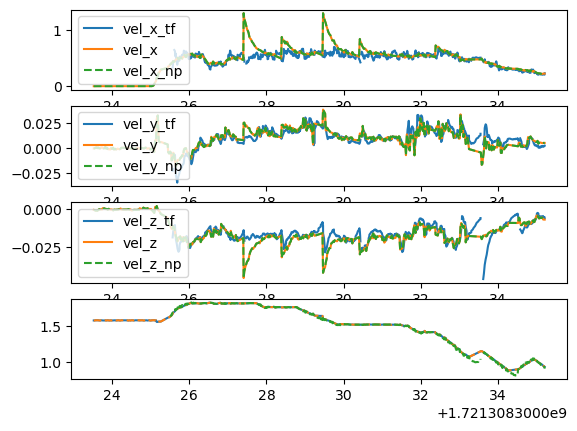

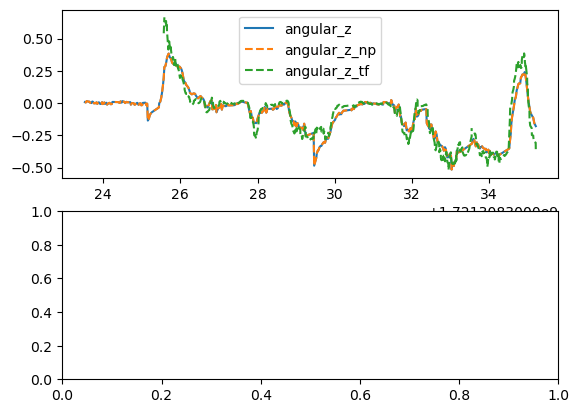

In [2]:
from social_evaluation.utils.utils import *
from tf_transformations import euler_from_quaternion, compose_matrix, decompose_matrix, quaternion_from_euler, inverse_matrix

df_map_base_link, dt = compute_odometry_data(df_map_base_link, period=5)

vel_x_mp_bl = np.array(df_map_base_link['velocity_x'])
vel_y_mp_bl = np.array(df_map_base_link['velocity_y'])
vel_z_mp_bl = np.array(df_map_base_link['velocity_z'])
time_mp_bl = np.array(df_map_base_link['time'])

vel_y = np.array(df_interpolated['velocity_y'])
vel_y_np = np.array(df['velocity_y'])
vel_z = np.array(df_interpolated['velocity_z'])
vel_z_np = np.array(df['velocity_z'])
dt = np.array(dt)

yaw = np.array(df_interpolated['yaw'])
yaw_np = np.array(df['yaw'])
yaw_map_base_link = np.array(df_map_base_link['yaw'])

fig, ax = plt.subplots(4, 1)

ax[0].plot(time_mp_bl, vel_x_mp_bl, label='vel_x_tf')
ax[0].plot(time, vel_x, label='vel_x')
ax[0].plot(time_np, vel_x_np, label='vel_x_np', linestyle='--')


# ax[0].axvline(x=time_goal_reached, color='r', linestyle='--')

ax[0].legend()
ax[1].plot(time_mp_bl, vel_y_mp_bl, label='vel_y_tf')
ax[1].plot(time, vel_y, label='vel_y')
ax[1].plot(time_np, vel_y_np, label='vel_y_np', linestyle='--')
ax[1].legend()
ax[2].plot(time_mp_bl, vel_z_mp_bl, label='vel_z_tf')
ax[2].plot(time, vel_z, label='vel_z')
ax[2].plot(time_np, vel_z_np, label='vel_z_np', linestyle='--')
ax[2].legend()
ax[3].plot(time, yaw, label='yaw')
ax[3].plot(time_np, yaw_np, label='yaw_np', linestyle='--')
ax[3].plot(time_mp_bl, yaw_map_base_link, label='yaw_tf', linestyle='--')
# ax[3].legend()

# min_distance = min(df_map_base_link.apply(lambda x: np.linalg.norm([x['position_x'] - goal[0], x['position_y'] - goal[1]]), axis=1))
# min_distance = min(df_map_base_link.apply(lambda x: np.linalg.norm([x['position_x'] - goal[0], x['position_y'] - goal[1]]), axis=1))

angular_z = np.array(df_interpolated['angular_velocity_z'])
angular_z_np = np.array(df['angular_velocity_z'])
angular_z_map_base_link = np.array(df_map_base_link['angular_velocity_z'])
angular_x = np.array(df_interpolated['angular_velocity_x'])
angular_x_np = np.array(df['angular_velocity_x'])
angular_x_map_base_link = np.array(df_map_base_link['angular_velocity_x'])
angular_y = np.array(df_interpolated['angular_velocity_y'])
angular_y_np = np.array(df['angular_velocity_y'])
angular_y_map_base_link = np.array(df_map_base_link['angular_velocity_y'])
fig, ax = plt.subplots(2, 1)
ax[0].plot(time, angular_z, label='angular_z')
ax[0].plot(time_np, angular_z_np, label='angular_z_np', linestyle='--')
ax[0].plot(time_mp_bl, angular_z_map_base_link, label='angular_z_tf', linestyle='--')
ax[0].legend()
# ax[1].plot(time, angular_x, label='angular_x')
# ax[1].plot(time_np, angular_x_np, label='angular_x_np', linestyle='--')
# ax[1].plot(time_mp_bl, angular_x_map_base_link, label='angular_x_tf', linestyle='--')
# ax[1].legend()
# ax[2].plot(time, angular_y, label='angular_y')
# ax[2].plot(time_np, angular_y_np, label='angular_y_np', linestyle='--')
# ax[2].plot(time_mp_bl, angular_y_map_base_link, label='angular_y_tf', linestyle='--')
# ax[2].legend()

/home/andrea/workspaces/appl_ws/social_evaluation/social_evaluation/utils/metrics.py:68: FutureWarning: DataFrame.interpolate with object dtype is deprecated and will raise in a future version. Call obj.infer_objects(copy=False) before interpolating instead.
  df_agents = df_agents.interpolate(method="cubic", order=3)
/home/andrea/workspaces/appl_ws/social_evaluation/social_evaluation/utils/metrics.py:83: FutureWarning: DataFrame.interpolate with object dtype is deprecated and will raise in a future version. Call obj.infer_objects(copy=False) before interpolating instead.
  df_agents = df_agents.interpolate(method="cubic", order=3)


0.1737362463062167
groups: []


KeyError: 'position_x'

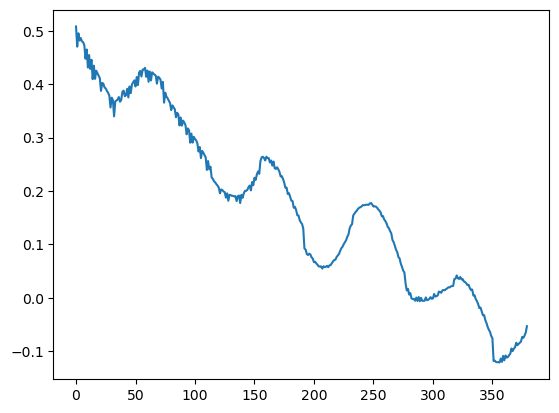

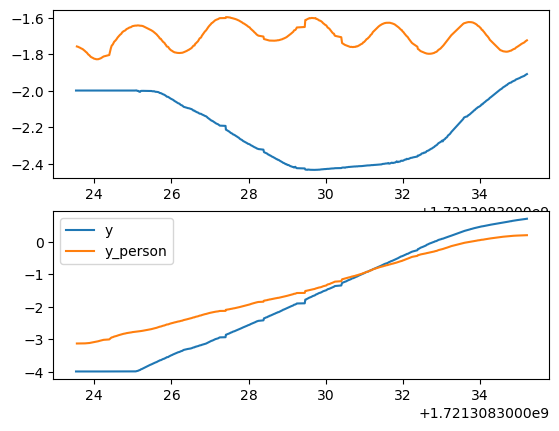

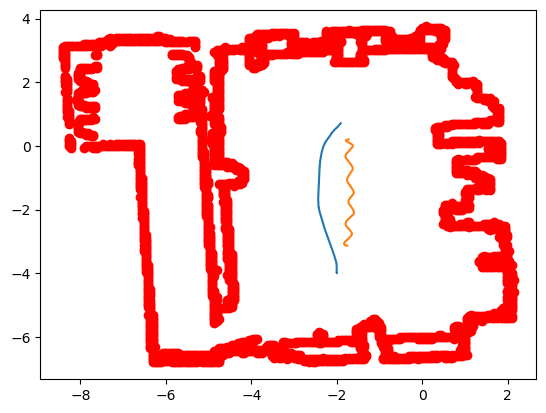

In [4]:
person_name = 'U_1.U_1'
df_person = get_person_data(df_people, person_name)
df_person



min, df_avg =avg_closest_person([df_person], df_map_base_link, 0.3, 0.3)
print(min)

groups = detect_groups([df_person])
print(f'groups: {groups}')

fig, ax = plt.subplots(1, 1)
avg_dist = np.array(df_avg['min_distance'])
# time_dist = np.array(df_avg['time'])
ax.plot(avg_dist, label='avg_dist')

df_agents = df_odometry.combine_first(df_people)
x_person = np.array(df_person['position_x'])
y_person = np.array(df_person['position_y'])
time_person = np.array(df_person['time'])

fig , ax = plt.subplots(2, 1)
ax[0].plot(time, x, label='x')
ax[0].plot(time_person, x_person, label='x_person')

ax[1].plot(time, y, label='y')
ax[1].plot(time_person, y_person, label='y_person')

plt.legend()

fig , ax = plt.subplots(1, 1)
ax.plot(x, y, label='robot')
ax.plot(x_person, y_person, label='person')

group_intimate_space_intrusions([df_person], df_map_base_link)

social_map_path = "/home/andrea/workspaces/appl_ws/social_evaluation/maps/covivio_v1.yaml"

map , map_info = get_map_data(social_map_path)
import matplotlib.pyplot as plt


# plt.imshow(map, cmap='gray')

df_obs = retrieve_obstacle_positions(map, map_info)


# df_obs.plot(x='x', y='y', kind='scatter', color='red')
obs_position_x = np.array(df_obs['x'])
obs_position_y = np.array(df_obs['y'])

ax.plot(obs_position_x, obs_position_y, 'ro')
closest_obs = find_closest_obstacle(df_map_base_link, df_obs)


In [ ]:
def time_not_moving(
    df_robot: pd.DataFrame, period: int = 1,
    min_velocity: float = 0.5, min_angular_velocity: float = 0.2
) -> Tuple[float, pd.DataFrame]:
    """Compute the time the robot is not moving"""
    not_moving = df_robot.apply(
        lambda x: (
            1 if x["velocity_x"] < min_velocity and abs(x["angular_velocity_z"] < min_angular_velocity) else 0
        ),
        axis=1,
    )
    time_stopped = df_robot.time.diff(periods=period) * not_moving
    return time_stopped, not_moving

time_stopped, not_moving = time_not_moving(df_map_base_link, 1)
print(time_stopped.sum())
print(not_moving.sum())
print(time_stopped.shape)
print(not_moving.shape)






3.1471054553985596
235
(744,)
(744,)


In [ ]:
# combine_df_agents([df_person])
# combine_df_robot_agents(df_map_base_link, [df_person])

# closest_agent_to_robot(df_map_base_link, [df_person])

avg_closest_pedestrian_velocity(df_map_base_link, [df_person])
avg_pedestrian_velocity([df_person])

/home/andrea/workspaces/appl_ws/social_evaluation/social_evaluation/utils/metrics.py:68: FutureWarning: DataFrame.interpolate with object dtype is deprecated and will raise in a future version. Call obj.infer_objects(copy=False) before interpolating instead.
  df_agents = df_agents.interpolate(method="cubic", order=3)
/home/andrea/workspaces/appl_ws/social_evaluation/social_evaluation/utils/metrics.py:83: FutureWarning: DataFrame.interpolate with object dtype is deprecated and will raise in a future version. Call obj.infer_objects(copy=False) before interpolating instead.
  df_agents = df_agents.interpolate(method="cubic", order=3)
/home/andrea/workspaces/appl_ws/social_evaluation/social_evaluation/utils/metrics.py:68: FutureWarning: DataFrame.interpolate with object dtype is deprecated and will raise in a future version. Call obj.infer_objects(copy=False) before interpolating instead.
  df_agents = df_agents.interpolate(method="cubic", order=3)
/home/andrea/workspaces/appl_ws/social_e

(0.353598044110102,
 0      0.098957
 1      0.092456
 2      0.089685
 3      0.087479
 4      0.086298
          ...   
 456    0.123368
 457    0.122435
 458    0.120590
 459    0.128429
 460    0.130007
 Name: avg_pedestrian_velocity, Length: 461, dtype: float64)

In [ ]:
config = {
    "force_factor_desired": 2.0,
    "force_factor_obstacle": 10,
    "force_factor_social": 2.1,
    "force_factor_group_gaze": 3.0,
    "force_factor_group_coherence": 2.0,
    "force_factor_group_repulsion": 1.0,
    "force_sigma_obstacle": 0.2,
    "lambda_": 2.0,
    "gamma": 0.35,
    "n": 2.0,
    "n_prime": 3.0,
    "relaxation_time": 0.5,
    "goal_radius": 0.2,  # agent goal radius
    "desired_velocity": 0.5,  # agent desired velocity
}

def compute_social_force_two_agents(
    df_agent1: pd.DataFrame,
    df_agent2: pd.DataFrame,
    lambda_: float = config["lambda_"],
    gamma: float = config["gamma"],
    n: float = config["n"],
    n_prime: float = config["n_prime"],
    force_factor_social: float = config["force_factor_social"],
):
    df_interaction = df_agent1.merge(df_agent2, on="time", suffixes=("_1", "_2"))
    df_interaction.dropna(inplace=True)
    df_interaction.reset_index(drop=True, inplace=True)
    
    df_interaction["diff"] = df_interaction[["position_x_1", "position_y_1"]].apply(lambda x: np.array([x[0], x[1]]), axis=1) - df_interaction[["position_x_2", "position_y_2"]].apply(lambda x: np.array([x[0], x[1]]), axis=1)
    df_interaction["diff_norm"] = df_interaction.apply(lambda x: np.linalg.norm(x["diff"]), axis=1)
    df_interaction["diff_direction"] = df_interaction.apply(lambda x: x["diff"] / x["diff_norm"], axis=1)

    df_interaction["vel_diff"] = df_interaction[["velocity_x_1", "velocity_y_1"]].apply(lambda x: np.array([x[0], x[1]]), axis=1) - df_interaction[["velocity_x_2", "velocity_y_2"]].apply(lambda x: np.array([x[0], x[1]]), axis=1)
    df_interaction["interaction_vector"] = df_interaction["diff"] + lambda_ * df_interaction["vel_diff"]
    df_interaction["interaction_length"] = df_interaction["interaction_vector"].apply(
        np.linalg.norm
    )
    df_interaction["interaction_direction"] = df_interaction["interaction_vector"].apply(lambda x: x / np.linalg.norm(x))
    df_interaction["theta"] = df_interaction.apply(lambda x: np.arctan2(x["diff"][1], x["diff"][0]) - np.arctan2(x["interaction_direction"][1], x["interaction_direction"][0]), axis=1)
    df_interaction["theta"] = df_interaction["theta"].apply(normalize_angle)

    df_interaction["B"] = gamma * df_interaction["interaction_length"]
    df_interaction["force_velocity_amount"] = df_interaction.apply(lambda x: -np.exp(- x["diff_norm"] / x["B"] - (n_prime * x["B"] * x["theta"]) ** 2), axis=1)
    df_interaction["force_angle_amount"] = df_interaction.apply(lambda x: -np.sign(x["theta"]) * np.exp(-x["diff_norm"] / x["B"] - (n * x["B"] * x["theta"]) ** 2), axis=1)

    # df_interaction["force_velocity"] = (
    #     df_interaction["force_velocity_amount"]
    #     * df_interaction["interaction_direction"]
    # )
    df_interaction["force_velocity"] = df_interaction["force_velocity_amount"] * df_interaction["interaction_direction"]
    df_interaction["interaction_direction_left_normal"] = df_interaction[
        "interaction_direction"
    ].apply(lambda x: np.array([-x[1], x[0]]))
    df_interaction["force_angle"] = (
        df_interaction["force_angle_amount"]
        * df_interaction["interaction_direction_left_normal"]
    )
    df_interaction["social_force"] = force_factor_social * (
        df_interaction["force_velocity"] + df_interaction["force_angle"]
    )
    return df_interaction["social_force"]
    # return df_interaction

df_social_force = compute_social_force_two_agents(df_map_base_link, df_person)

/tmp/ipykernel_150565/1766215327.py:31: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  df_interaction["diff"] = df_interaction[["position_x_1", "position_y_1"]].apply(lambda x: np.array([x[0], x[1]]), axis=1) - df_interaction[["position_x_2", "position_y_2"]].apply(lambda x: np.array([x[0], x[1]]), axis=1)
/tmp/ipykernel_150565/1766215327.py:31: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  df_interaction["diff"] = df_interaction[["position_x_1", "position_y_1"]].apply(lambda x: np.array([x[0], x[1]]), axis=1) - df_interaction[["position_x_2", "position_y_2"]].apply(lambda x: np.array([x[0], x[1]]), axis=1)
/tmp/ipyke

In [12]:
from social_evaluation.utils import *
from matplotlib import pyplot as plt
import numpy as np
# from social_evaluation import bag_extraction
import yaml

config = yaml.load(open('/home/andrea/workspaces/appl_ws/social_evaluation/social_evaluation/config/config.yaml'), Loader=yaml.FullLoader)
experiment_names = config['experiment_names']
algorithms = config['algorithms']
experiment_ids = config['experiment_ids']
base_path = config['base_path']
bag_paths = []
for experiment_name in experiment_names:
    for algorithm in algorithms:
        for i in experiment_ids:
            bag_path = get_bag_path(experiment_name, algorithm, base_path, i)
            bag_paths.append(bag_path)

print(bag_paths)

config_tf = config['transforms']
transforms = {}
for transform in config_tf:
    print(transform)
    print(transform.items())
    for transform_name, transform_config in transform.items():
        frame_id = transform_config["frame_id"]
        child_frame_id = transform_config["child_frame_id"]
        transformations_parent_child = []
        for timestamp in filter_df_by_time(df_tf)['time']:
            transformations_parent_child.append(
                pd.Series(
                    {
                        'time':timestamp,
                        **get_pose_data_from_transform(get_transform_between_frames(df_tf, frame_id, child_frame_id, timestamp))}
                                               )
            )
        transforms[transform_name] = pd.DataFrame(transformations_parent_child)

transforms

data = {}

for bag_path in bag_paths:
    data[bag_path] = transforms
import pickle

with open('data.pickle', 'wb') as handle:
    print('saving data')
    pickle.dump(data, handle, protocol=pickle.HIGHEST_PROTOCOL)


['/home/andrea/workspaces/appl_ws/bags/overtaking/DWA/scenario_1/scenario_1_0.db3']
{'map_to_base_link': {'child_frame_id': 'base_link', 'frame_id': 'map'}}
dict_items([('map_to_base_link', {'child_frame_id': 'base_link', 'frame_id': 'map'})])
saving data


In [1]:
# clear data
data = None
import pickle
with open('data.pickle', 'rb') as handle:
    print('loading data')
    data = pickle.load(handle)

loading data
